In [145]:
!pip install graphviz

# Backpropagation and computation graph

The objective of the current exercise is to introduce how works a deep-learning library. To this end we will devellop in this exercise a python library that build a computational using only scalar operations (consequently it is not yet necessary to use numpy library).

The main object we will manipulate will be the ComputationalGraphNode, this object (or class in python) will have different methods and attributes (discuted during the lecture session). 
We will consider two type of nodes, a classical nodes and parameters node (that will sum the gradient at each backward step).


**Below a code for printing the graphs ! Do not modify the code** 


In [146]:
import graphviz
name_operation_list = {'Addition': '+', 'Multiplication': '*', 'Substraction': '-'}
def createbackwardgraph(root, parent_index=None, graph=None, nodelist={}, edge_list=set()):
    if graph is None:
        graph = graphviz.Digraph(filename = "digraph.gv")
    
    if root not in nodelist:
        nodelist[root] = str(len(nodelist))

        node_name = root.name if 'name' in root.__dict__ else "unknow"
        if root.gradient_function is not None:
            node_name = root.gradient_function.__qualname__.split(".")[0] + " : " + node_name
        node_name += f'\n v = {root.value} \n g = {root.cumulative_gradient}' 

        parent_index = nodelist[root]
        graph.node(parent_index, node_name)


    if root.previous_node_list is None:
        return

    for node in root.previous_node_list:

        if node not in nodelist:
            nodelist[node] = str(len(nodelist))

            node_name = node.name if 'name' in node.__dict__ else "unknow"
            if node.gradient_function is not None:
                node_name = node.gradient_function.__qualname__.split(".")[0] + " : " + node_name
            node_name += f'\n v = {node.value} \n g = {node.cumulative_gradient}' 

            node_index = nodelist[node]
            graph.node(node_index, node_name)
        if not (nodelist[node], nodelist[root]) in edge_list:
            edge_list.add((nodelist[node], nodelist[root]))
            graph.edge(nodelist[node], nodelist[root])
        elif root.previous_node_list[0] ==  root.previous_node_list[-1]: 
            graph.edge(nodelist[node], nodelist[root])
        createbackwardgraph(node, None, graph=graph, nodelist=nodelist, edge_list=edge_list)
    return graph


## Implement the computational graph node

A node of the computation graph needs to store different information :
* A backward operation (computing gradient of the model according to its input)
* The value of the node (a float)
* The gradient of the node (updated/accumulated when backward is called)
* The list of previous nodes (input that produced the current node)

In [147]:
from typing import List, Tuple

class ComputationGraphNode(object):
    def __init__(self, value : float, gradient_function = None , previous_node_list: List = None, name=None):
        if name is not None:
            self.name = name
        self.value = value
        self.cumulative_gradient = .0
        self.gradient_function = gradient_function
        self.previous_node_list = previous_node_list

    def __str__(self) -> str:
        return f'ComputationGraphNode with value = {self.value}'
    def __repr__(self) -> str :
        return f'ComputationGraphNode with value = {self.value}'

    def backward(self, gradient : float = 1.) -> float:
        self.cumulative_gradient += gradient
        if self.gradient_function is not None and self.previous_node_list is not None:
            grads = self.gradient_function(*self.previous_node_list, gradient)
            if not isinstance(grads, (list, tuple)):
                grads = (grads,)
            for prev_node, local_grad in zip(self.previous_node_list, grads):
                prev_node.backward(gradient * local_grad)
        return self.cumulative_gradient

        # call backward with on the previous node (with correct gradient)
 

class Parameter(ComputationGraphNode):
    def backward(self, gradient=1) -> float:
        self.cumulative_gradient += gradient

## implement add, mul, sub and relu operations

For each operations we should define a forward function and a gradient_function function. To ease the implementation we will consider an operation as an object that:
* In the method forward takes previous nodes and compute the net node
* In backward methods takes previous input nodes and compute the gradient for each input node


Implement the methods of the following operations :

In [148]:
class Operation(object):
    @staticmethod
    def forward(*args, **kwargs) -> Tuple[float]:
        raise NotImplementedError("This is an abstract class, you should inherit from the class")
    @staticmethod
    def gradient_function(*args, **kwargs) -> ComputationGraphNode:
        raise NotImplementedError("This is an abstract class, you should inherit from the class")

class Addition(object):
    @staticmethod
    def gradient_function(node_a: ComputationGraphNode, node_b: ComputationGraphNode, output_grad: float):
        return output_grad, output_grad
        
    @staticmethod
    def forward(node_a: ComputationGraphNode, node_b: ComputationGraphNode):
        return ComputationGraphNode(node_a.value + node_b.value, Addition.gradient_function, [node_a, node_b])

class Substraction(object):
    @staticmethod
    def gradient_function(node_a: ComputationGraphNode, node_b: ComputationGraphNode, output_grad: float):
        return output_grad, -output_grad
    @staticmethod
    def forward(node_a: ComputationGraphNode, node_b: ComputationGraphNode):
        return ComputationGraphNode(node_a.value - node_b.value, Substraction.gradient_function, [node_a, node_b], name="Substraction")
    


class Multiplication(object):
    @staticmethod
    def gradient_function(node_a: ComputationGraphNode, node_b: ComputationGraphNode, output_grad: float):
        return output_grad * node_b.value, output_grad * node_a.value

    @staticmethod
    def forward(node_a: ComputationGraphNode, node_b: ComputationGraphNode):
        return ComputationGraphNode(node_a.value * node_b.value, Multiplication.gradient_function, [node_a, node_b], name="Multiplication")

class ReLU(object):
    @staticmethod
    def gradient_function(node_a: ComputationGraphNode, output_grad: float):
        return output_grad if node_a.value > 0 else 0.0

    @staticmethod
    def forward(node_a: ComputationGraphNode):
        return ComputationGraphNode(max(0.0, node_a.value), ReLU.gradient_function, [node_a], name="ReLU")


### Overloading the operators (not necessary, but easier to use)

In [149]:
ComputationGraphNode.__add__ = Addition.forward
ComputationGraphNode.__sub__ = Substraction.forward
ComputationGraphNode.__mul__ = Multiplication.forward

**Code/propose different examples and verify that when calling backward on the last node you obtain the correct gradient !!**


NB : You can use createbackwardgraph(loss) to show the computation graph and values

In [150]:
x1 = ComputationGraphNode(.1, name='x1')
x2 = ComputationGraphNode(1.0, name='x2')
print(x1, x2)

ComputationGraphNode with value = 0.1 ComputationGraphNode with value = 1.0


## Create a module that apply linear transformation

We consider now a new class namely Module, all the module you will implement will inherit from this class. Notice also that module may have parameters (node of type `Parameter`) that will be returned calling `my_module.parameter`


In [151]:
class Module:
    def __init__(self):
        raise NotImplemented("")
        
    def parameters(self):
        ret = []
        for name in dir(self):
            o = self.__getattribute__(name)

            if type(o) is Parameter:
                ret.append(o)
            if isinstance(o, Module) or isinstance(o, ModuleList):
                ret.extend(o.parameters())
        return ret

class ModuleList(list):
    def parameters(self):
        ret = []
        for m in self:
            if type(m) is Parameter:
                ret.append(m)
            elif isinstance(m, Module) or isinstance(m, ModuleList):
                ret.extend(m.parameters())
        return ret

Implement the two modules :

* Linear which apply on a list of node a linear transformation with bias $Wx^t + b$
* The relu function that compute from a list the relu for each element

In [152]:
import random
class Linear(Module):
    def __init__(self, input_size, output_size):
        self.weights = ModuleList([ModuleList([Parameter(random.random() - 0.5) for i in range(input_size)]) for j in range(output_size)])
        self.bias = ModuleList([Parameter(0.01) for _ in range(output_size)])

    def __call__(self, node_list : List[ComputationGraphNode]) -> List[ComputationGraphNode]:
        output = []
        for i in range(len(self.weights)):
            out_node = self.bias[i]
            for j in range(len(node_list)):
                out_node = out_node + self.weights[i][j] * node_list[j]
            output.append(out_node)
        return output

def relu(x_list : List[ComputationGraphNode]) -> List[ComputationGraphNode]:
    return [ReLU.forward(x) for x in x_list]

l = Linear(2, 3)
l([Parameter(0), Parameter(1)])

[ComputationGraphNode with value = -0.1139242513602169,
 ComputationGraphNode with value = 0.16519000206804257,
 ComputationGraphNode with value = -0.14051576398300647]

In [153]:
l.parameters()

[ComputationGraphNode with value = 0.01,
 ComputationGraphNode with value = 0.01,
 ComputationGraphNode with value = 0.01,
 ComputationGraphNode with value = -0.3005562481182834,
 ComputationGraphNode with value = -0.1239242513602169,
 ComputationGraphNode with value = 0.4450203249971809,
 ComputationGraphNode with value = 0.15519000206804257,
 ComputationGraphNode with value = 0.28581934391589603,
 ComputationGraphNode with value = -0.15051576398300648]

## Create your network similarly
Create a two layer networks with as activation a sigmoid function :
* input_size being the size of the input X
* intermediate_size the hidden layer size
* output_size the size of the outpu (for binary classification it is 1)


In [154]:
class MyTwoLayerNetwork(Module):
    def __init__(self, input_size, intermediate_size, output_size = 1):
        ### Initialise submodule necessary for computation 
        self.layer1 = Linear(input_size, intermediate_size)
        self.layer2 = Linear(intermediate_size, output_size)  
    def forward(self, node_list : List[ComputationGraphNode]) -> List[ComputationGraphNode]:
        hidden = self.layer1(node_list)
        hidden_act = relu(hidden)
        output = self.layer2(hidden_act)
        return output
        
    def __call__(self, node_list : List[ComputationGraphNode]) -> List[ComputationGraphNode]: 
        return self.forward(node_list) 


### Implement the following functions :
* hing_loss computing the hinge loss from node
* update_weight that will update all the weights given in parameters $\theta^t = \theta^{t-1}  - \lambda \nabla_{\theta^{t-1}} L$
* zero_grad that set all accumulated gradient of the nodes to 0

In [155]:
## Create your loss function

def hinge_loss(x : ComputationGraphNode, y: ComputationGraphNode):
    return  ReLU.forward(ComputationGraphNode(1) - x * y)

def update_weight(parameter_list : List[ComputationGraphNode], learning_rate: float):
    for param in parameter_list: 
        param.value -= learning_rate * param.cumulative_gradient
def zero_grad(parameter_list):
    for param in parameter_list: 
        param.cumulative_gradient = 0.0


## Build a network that can solve the following problem

Train your network on the following dataset and provide accuracy of the model on the training data (only for this example else consider separated trianing and testing set)

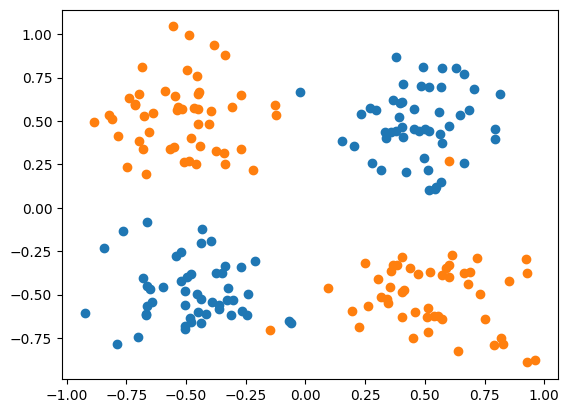

In [156]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
dataset = list(zip(np.random.randn(50,2)*0.2 + [0.5, 0.5], np.ones(50))) \
               + list(zip(np.random.randn(50,2)*0.2 + [-0.5, 0.5], np.zeros(50)))\
               + list(zip(np.random.randn(50,2)*0.2 + [0.5, -0.5], np.zeros(50))) \
               +  list(zip(np.random.randn(50,2)*0.2 + [-0.5, -0.5], np.ones(50)))
X, Y = np.array([x for (x, _) in dataset]), np.array([y for (_, y) in dataset]) 

plt.scatter(X[Y==1][:, 0],X[Y==1][:, 1])
plt.scatter(X[Y==0][:, 0],X[Y==0][:, 1])

In [157]:
model = MyTwoLayerNetwork(2, 4, 1)

In [158]:
n_epoch = 30
w = [0.1, 0.1]
b = 0.1
learning_rate = 1e-3
parameter_list = model.parameters()
for epoch in range(n_epoch):
    loss_values = []
    shuffled_index = np.arange(len(X))
    np.random.shuffle(shuffled_index)
    
    for i in shuffled_index:
        x, y = X[i], Y[i]
        x_nodes = [ComputationGraphNode(val) for val in x]
        y_label = 1.0 if y == 1 else -1.0
        y_node = ComputationGraphNode(y_label)
        pred = model(x_nodes)[0]
        loss = hinge_loss(pred, y_node)
        loss.backward()
        loss_values.append(loss.value)

        update_weight(model.parameters(), learning_rate)
        zero_grad(model.parameters())

    #print(pred)
    print(f'The loss for the epoch {epoch} is {np.mean(loss_values)}')
    loss_values = []

The loss for the epoch 0 is 1.0256181509910025
The loss for the epoch 1 is 1.0316953598998657
The loss for the epoch 2 is 1.026189677913649
The loss for the epoch 3 is 1.0309378503417304
The loss for the epoch 4 is 1.0354043644878645
The loss for the epoch 5 is 1.0761947818691926
The loss for the epoch 6 is 1.1296008491263363
The loss for the epoch 7 is 1.1834275224027826
The loss for the epoch 8 is 1.2372518132147547
The loss for the epoch 9 is 1.2910727016220118
The loss for the epoch 10 is 1.3448887380320138
The loss for the epoch 11 is 1.3986979261730135
The loss for the epoch 12 is 1.4524975907211637
The loss for the epoch 13 is 1.5062842272013726
The loss for the epoch 14 is 1.560053105552032
The loss for the epoch 15 is 1.613797970057331
The loss for the epoch 16 is 1.6675108057983499
The loss for the epoch 17 is 1.721181079943397
The loss for the epoch 18 is 1.7747958442052008
The loss for the epoch 19 is 1.8283387871777486
The loss for the epoch 20 is 1.8817885308648998
The lo

### Evaluate accuracy

In [159]:
# test 
score = 0
for i in shuffled_index:
    x, y = X[i], Y[i]
    pred = model.forward([ComputationGraphNode(x_val) for x_val in x])
    score += 1 if (pred[0].value *  (2 * y - 1)  > 0) else  0
score/len( X)

0.5